# Cambridge Residential Property Values by Neighborhood (FY2026)

Choropleth maps and supporting analysis of assessed property values across Cambridge's thirteen CDD neighborhoods, using the Cambridge Property Database (Socrata `eey2-rv59`).

## What this notebook covers

| Section | Output |
|---------|--------|
| Neighborhood statistics | Printed tables |
| Assessed value per residential unit | `../data/out/assessed_value_per_unit_map.png` |
| Mean units per residential building | `../data/out/units_per_building_map.png` |
| % single-family homes | `../data/out/pct_sfh_map.png` |
| Value distribution by neighborhood (KDE) | `../data/out/value_distribution.png` |
| Assessment accuracy (assessed vs. sale price) | `../data/out/assessment_ratio_map.png`, `../data/out/assessment_ratio_distribution.png` |

For the West Cambridge tenure and tax equity analysis, see **`03_west_cambridge_equity.ipynb`**.

## Key data decisions

**Which residential codes to include:**
The dataset uses Massachusetts state class codes. We include codes that represent occupied residential property:

| Code | Type | Included | Rationale |
|------|------|----------|-----------|
| 101 | Single-family | ✓ | Core residential |
| 102 | Condo unit | ✓ | Individual units |
| 104 | 2-family | ✓ | |
| 105 | 3-family | ✓ | |
| 106 | 4–6 unit | ✓ | |
| 109 | Apt 7+ | ✓ | |
| 111–114 | Mixed-use / other res | ✓ | |
| 121 | Other residential | ✓ | |
| 13 | Res (alternate code) | ✓ | Small count, same population |
| 199 | Condo master record | ✗ | Building-level record; including it would double-count condo assessed values alongside code 102 unit records |
| 122–123 | Frats / dorms | ✗ | Institutional, not residential market |
| 130–132 | Vacant land | ✗ | No structure |
**What these counts cover:** The residential codes above yield ~47,200 housing units and ~21,600 properties in FY2026. This represents the privately-owned residential stock — including ~1,600 deed-restricted inclusionary zoning (IZ) units and ~150 scattered-site homeownership units, which are assessed under standard residential codes. It excludes ~2,800 public housing units managed by the Cambridge Housing Authority (CHA), university-owned housing (Harvard, MIT, Lesley), and other institutionally-owned dwellings on tax-exempt land. The city's total housing stock is 58,966 units (CDD Land Use Data, June 2025); the difference is primarily CHA and university housing classified under non-residential or tax-exempt assessment codes.

**Condo coordinate fix:** Individual condo unit records (code 102) carry no lat/lon. We borrow coordinates from the parent condo-building record (code 199), matched by `gisid`. FY2026 match rate: ~99%.

**Units per property:** Code 102 (individual condo unit) imputes `numunits = 1` since `interior_numunits` is not populated. All other codes use `interior_numunits`, clipped to ≥ 1.

**Assessment year:** FY2026 only for the neighborhood snapshot. `saledate`/`saleprice` in FY2026 records reflect the most recent recorded conveyance for each property — not a 2026 transaction.

## Area 2/MIT

The MIT neighborhood (Area 2/MIT) **is excluded from all choropleth maps and from the assessment ratio analysis**. It contains only 3 residential records in FY2026, all assessed at institutional land values (~$24M mean), making neighborhood-level metrics meaningless. The MIT boundary is a distinct CDD polygon from the West Cambridge neighborhood.

> **TODO for reviewers:** Confirm whether to exclude Area 2/MIT from the KDE distribution chart (currently it is excluded from choropleths but included in the citywide distribution since we filter to specific neighborhoods by name there).


In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

DATA_RAW = Path("../data/raw")
DATA_OUT = Path("../data/out")
DATA_OUT.mkdir(parents=True, exist_ok=True)

PROP_CSV            = DATA_RAW / "cambridge_property_assessments.csv"
NEIGHBORHOODS_GEOJSON = DATA_RAW / "CDD_Neighborhoods.geojson"

assert PROP_CSV.exists(), f"Run scripts/fetch_property_assessments.py first: {PROP_CSV}"
assert NEIGHBORHOODS_GEOJSON.exists(), f"Missing: {NEIGHBORHOODS_GEOJSON}"

df            = pd.read_csv(PROP_CSV)
neighborhoods     = gpd.read_file(NEIGHBORHOODS_GEOJSON).to_crs("EPSG:4326")
neighborhoods_utm = neighborhoods.to_crs("EPSG:32619")   # for plotting
MIT_NAME          = "Area 2/MIT"                          # excluded from choropleths

print(f"Loaded {len(df):,} property records ({df['yearofassessment'].nunique()} assessment years)")
print(f"Years: {sorted(df['yearofassessment'].dropna().astype(int).unique())}")
print(f"Neighborhoods: {sorted(neighborhoods['NAME'].tolist())}")


Loaded 323,748 property records (11 assessment years)
Years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Neighborhoods: ['Area 2/MIT', 'Baldwin', 'Cambridge Highlands', 'Cambridgeport', 'East Cambridge', 'Mid-Cambridge', 'Neighborhood Nine', 'North Cambridge', 'Riverside', 'Strawberry Hill', 'The Port', 'Wellington-Harrington', 'West Cambridge']


In [ ]:
import os, datetime

# Data provenance — run this cell to confirm what data is loaded
cache_mtime = datetime.datetime.fromtimestamp(os.path.getmtime(PROP_CSV))
print("=== Data provenance ===")
print(f"  File:         {PROP_CSV}")
print(f"  Last fetched: {cache_mtime.strftime('%Y-%m-%d %H:%M')}  (delete file and re-run fetch_property_assessments.py to refresh)")
print(f"  Rows:         {len(df):,}")
print(f"  Years in data: {sorted(df['yearofassessment'].dropna().astype(int).unique())}")
print(f"  Source:       City of Cambridge, Cambridge Property Database FY2016–FY2026")
print(f"  Socrata ID:   eey2-rv59  (https://data.cambridgema.gov/d/eey2-rv59)")
print(f"  Coverage:     All Cambridge parcels, all property classes, FY2016–FY2026")
print()
print(f"  Neighborhood boundaries: {NEIGHBORHOODS_GEOJSON}")
print(f"    Source: cambridgegis/cambridgegis_data (GitHub), CDD_Neighborhoods polygon")

## Building the Residential Dataset (FY2026)

We filter to FY2026 and the residential state class codes listed in the intro. The main processing steps are:

1. **Condo coordinate fix** — code 102 unit records carry no lat/lon; borrow from parent code 199 record via `gisid`
2. **Unit count** — code 102 imputes `numunits = 1`; others use `interior_numunits` (clipped ≥ 1)
3. **Value per unit** — `assessedvalue / numunits`
4. Drop rows missing coordinates or assessed value

The cell prints row counts and coordinate coverage as a sanity check.

In [2]:
YEAR = 2026

# Residential state class codes to include (exclude vacant land 130-132, dorms 123, frats 122, master condo records 199)
RES_CODES = {13, 101, 102, 104, 105, 106, 109, 111, 112, 113, 114, 121}

res = df[(df['yearofassessment'] == YEAR) & df['stateclasscode'].isin(RES_CODES)].copy()

# --- Coordinate fix for condos (code 102) ---
# Individual condo unit records have no lat/lon; borrow from parent condo-building (code 199) via shared gisid.
bldg_coords = (
    df[(df['yearofassessment'] == YEAR) & (df['stateclasscode'] == 199)]
    .groupby('gisid')[['latitude', 'longitude']]
    .first()
    .reset_index()
    .rename(columns={'latitude': 'bldg_lat', 'longitude': 'bldg_lon'})
)
res = res.merge(bldg_coords, on='gisid', how='left')
condo = res['stateclasscode'] == 102
res['latitude'] = res['latitude'].where(~condo | res['latitude'].notna(), res['bldg_lat'])
res['longitude'] = res['longitude'].where(~condo | res['longitude'].notna(), res['bldg_lon'])
res = res.drop(columns=['bldg_lat', 'bldg_lon'])

# --- Effective units & value per unit ---
# Condos: each record = 1 unit (interior_numunits not populated); all others use the field.
res['numunits'] = res['interior_numunits'].where(res['stateclasscode'] != 102, 1)
res['value_per_unit'] = res['assessedvalue'] / res['numunits'].clip(lower=1)

# Drop rows with no coordinates or no assessed value
res = res[res['latitude'].notna() & res['longitude'].notna() & res['assessedvalue'].notna()]

print(f"FY{YEAR} residential rows with coords and assessed value: {len(res):,}")
print(f"  of which condos (102): {(res['stateclasscode']==102).sum():,}")

# Build GeoDataFrame
gdf = gpd.GeoDataFrame(
    res,
    geometry=gpd.points_from_xy(res['longitude'], res['latitude']),
    crs='EPSG:4326'
)

FY2026 residential rows with coords and assessed value: 21,406
  of which condos (102): 13,123


## Spatial Join: Assigning Properties to Neighborhoods

Each property's lat/lon is tested against the CDD neighborhood polygons. Properties that fall outside all polygons (21 of 21,406 in FY2026) are unmatched — these are boundary edge cases likely just outside the polygon at parcel centroids. They are excluded from all neighborhood-level analysis.

**Area 2/MIT:** The 3 residential records in the MIT polygon are matched and retained in the `joined` dataframe but are excluded explicitly from all choropleth maps and from the assessment ratio analysis. They are **not** excluded from the KDE distribution chart since that chart filters by neighborhood name and MIT is not in its default selection — but see the TODO in the intro if you want to be explicit about this.

In [3]:
joined = gpd.sjoin(gdf, neighborhoods[['NAME', 'geometry']], how='left', predicate='within')
joined = joined.rename(columns={'NAME': 'neighborhood'})

matched = joined['neighborhood'].notna().sum()
print(f"Matched to neighborhood: {matched:,} / {len(joined):,} ({matched/len(joined)*100:.1f}%)")
print()

# Unmatched breakdown (boundary edge cases)
unmatched = joined[joined['neighborhood'].isna()]
if len(unmatched):
    print(f"Unmatched ({len(unmatched)} rows):")
    print(unmatched[['address', 'stateclasscode', 'latitude', 'longitude']].head(10).to_string(index=False))

Matched to neighborhood: 21,385 / 21,406 (99.9%)

Unmatched (21 rows):
           address  stateclasscode  latitude  longitude
     48 Harding St             105   42.3740   -71.0901
      2 Bedford St             101   42.3737   -71.0887
      15 Porter St             104   42.3737   -71.0884
    169 Tremont St             111   42.3744   -71.0966
 22 Springfield St             101   42.3744   -71.1006
    77 Francis Ave             104   42.3818   -71.1111
33-35-37 Harris St             105   42.3836   -71.1138
    64 Roseland St             101   42.3865   -71.1167
     16 Russell St             101   42.3923   -71.1228
     18 Russell St             104   42.3924   -71.1227


## Neighborhood Statistics (FY2026)

Three metrics are computed here and used by the choropleths below:

- **`val_stats`** — median and mean assessed value per unit, by neighborhood. Area 2/MIT excluded (see intro).
- **`pct_sfh_by_nbhd`** — single-family homes as % of *residential units* (not buildings). A 3-family building counted as 3 units; a SFH counted as 1. Area 2/MIT excluded.
- **`mean_units_by_nbhd`** — mean units per residential building. Uses a separate building-level dataset: non-condo buildings use `interior_numunits`; condo buildings use the count of code 102 unit records per `gisid` (the number of condo units in the building). Area 2/MIT excluded.

The summary table is printed below the cell. Inspect it before running the choropleth cells to catch any data anomalies.

In [4]:
# --- Assessed value per unit (from the residential unit-level spatial join) ---
val_stats = (
    joined[joined['neighborhood'].notna() & (joined['neighborhood'] != MIT_NAME)]
    .groupby('neighborhood')['value_per_unit']
    .agg(median='median', mean='mean', n='count')
    .rename_axis('NAME')
)

# --- % single-family: SFH units / total residential units ---
# joined is unit-level: condos = 1 row each, multi-family = 1 row with numunits > 1
pct_sfh_by_nbhd = (
    joined[joined['neighborhood'].notna() & (joined['neighborhood'] != MIT_NAME)]
    .groupby('neighborhood')
    .apply(lambda g: (g['stateclasscode'] == 101).sum() / g['numunits'].sum() * 100)
    .rename('pct_sfh')
    .rename_axis('NAME')
)

# --- Building-level stats: mean units/building (needs building-level dataset) ---
fy26_all  = df[df['yearofassessment'] == YEAR]
BLDG_CODES = {13, 101, 104, 105, 109, 111, 112, 113, 114, 121}

noncondo_b = (
    fy26_all[fy26_all['stateclasscode'].isin(BLDG_CODES)]
    .assign(numunits=lambda d: d['interior_numunits'].clip(lower=1))
    [['latitude', 'longitude', 'stateclasscode', 'numunits']]
    .dropna(subset=['latitude', 'longitude'])
)
condo_cnts = fy26_all[fy26_all['stateclasscode'] == 102].groupby('gisid').size().reset_index(name='numunits')
condo_b = (
    fy26_all[fy26_all['stateclasscode'] == 199]
    .merge(condo_cnts, on='gisid', how='inner')
    [['latitude', 'longitude', 'numunits']]
    .dropna(subset=['latitude', 'longitude'])
    .assign(stateclasscode=199)
)
bldg_df   = pd.concat([noncondo_b, condo_b], ignore_index=True)
bldg_gdf2 = gpd.GeoDataFrame(bldg_df, geometry=gpd.points_from_xy(bldg_df['longitude'], bldg_df['latitude']), crs='EPSG:4326')
bldg_sjoin = gpd.sjoin(bldg_gdf2, neighborhoods[['NAME', 'geometry']], how='left', predicate='within')
bldg_sjoin = bldg_sjoin[bldg_sjoin['NAME'].notna() & (bldg_sjoin['NAME'] != MIT_NAME)]

mean_units_by_nbhd = bldg_sjoin.groupby('NAME')['numunits'].mean().rename('mean_units')

# --- Summary table ---
summary = val_stats.join(mean_units_by_nbhd).join(pct_sfh_by_nbhd).sort_values('median', ascending=False)
summary.columns = ['Median $/unit', 'Mean $/unit', 'N units', 'Mean units/bldg', '% SFH']
print(f"FY{YEAR} neighborhood summary\n")
print(summary.round({'Median $/unit': 0, 'Mean $/unit': 0, 'N units': 0, 'Mean units/bldg': 1, '% SFH': 1}).to_string())

FY2026 neighborhood summary

                       Median $/unit  Mean $/unit  N units  Mean units/bldg  % SFH
NAME                                                                              
West Cambridge             1235100.0    2097371.0     2439              2.2   24.7
Baldwin                    1015800.0    1561631.0      802              3.8   10.5
Cambridgeport               891950.0    1039388.0     2392              4.6    6.0
Neighborhood Nine           877450.0    1299885.0     3302              4.9    9.8
Strawberry Hill             872875.0    1066675.0      516              3.1   11.8
North Cambridge             812150.0    1026219.0     2862              4.5    8.6
Cambridge Highlands         804550.0    1590466.0      302             12.1    5.5
Mid-Cambridge               800583.0    1000191.0     3466              5.3    4.8
Riverside                   778950.0     915101.0     1431              5.1    5.0
The Port                    768000.0     874922.0     1108

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

SERIF         = "DejaVu Serif"
NAME_FONTSIZE = 9
VAL_FONTSIZE  = 11
SOURCE_STR    = ("Source: City of Cambridge, Cambridge Property Database FY2016–FY2026, "
                 "data.cambridgema.gov/d/eey2-rv59")


def draw_choropleth(nbhd_gdf, cmap, norm, edge_color, txt_color, label_fn,
                    title, subtitle, out_path, fig_size=(11, 9)):
    """
    Draw a neighborhood choropleth matching the style of 01_affordable_housing_map.ipynb.
    nbhd_gdf must have columns 'NAME' and 'value' (NaN → shown as N/A in grey).
    """
    fig, ax = plt.subplots(figsize=fig_size)
    fig.patch.set_facecolor("#fafaf8")
    ax.set_facecolor("#fafaf8")
    fig.subplots_adjust(top=0.88)

    nbhd_gdf.plot(
        column="value", ax=ax, cmap=cmap, norm=norm, legend=False,
        edgecolor=edge_color, linewidth=1.6,
        missing_kwds={"color": "#d8d0c8", "edgecolor": edge_color, "linewidth": 1.6},
    )

    for _, row in nbhd_gdf.iterrows():
        x, y   = row.geometry.centroid.x, row.geometry.centroid.y
        is_na  = pd.isna(row.get("value"))
        val_lbl = "N/A" if is_na else label_fn(row["value"])
        bbox_kw = dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none")
        ax.annotate(row["NAME"], xy=(x, y), ha="center", va="bottom",
                    xytext=(0, 6), textcoords="offset points",
                    fontsize=NAME_FONTSIZE, color=txt_color,
                    bbox=bbox_kw)
        ax.annotate(val_lbl, xy=(x, y), ha="center", va="top",
                    xytext=(0, -6), textcoords="offset points",
                    fontsize=VAL_FONTSIZE, color=txt_color, fontweight="bold",
                    bbox=bbox_kw)

    ax.set_axis_off()
    fig.text(0.5, 0.95, title,    ha="center", va="top",
             fontsize=16, fontweight="bold", color="#2a1a0a", fontfamily=SERIF)
    fig.text(0.5, 0.91, subtitle, ha="center", va="top",
             fontsize=8.5, color="#6b5a4a")
    ax.annotate(SOURCE_STR, xy=(1, 0), xycoords="axes fraction",
                ha="right", va="top", fontsize=7.5, color="#9a8878",
                xytext=(0, -8), textcoords="offset points")

    plt.savefig(out_path, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved → {out_path}")

## Choropleth: median assessed value per residential unit

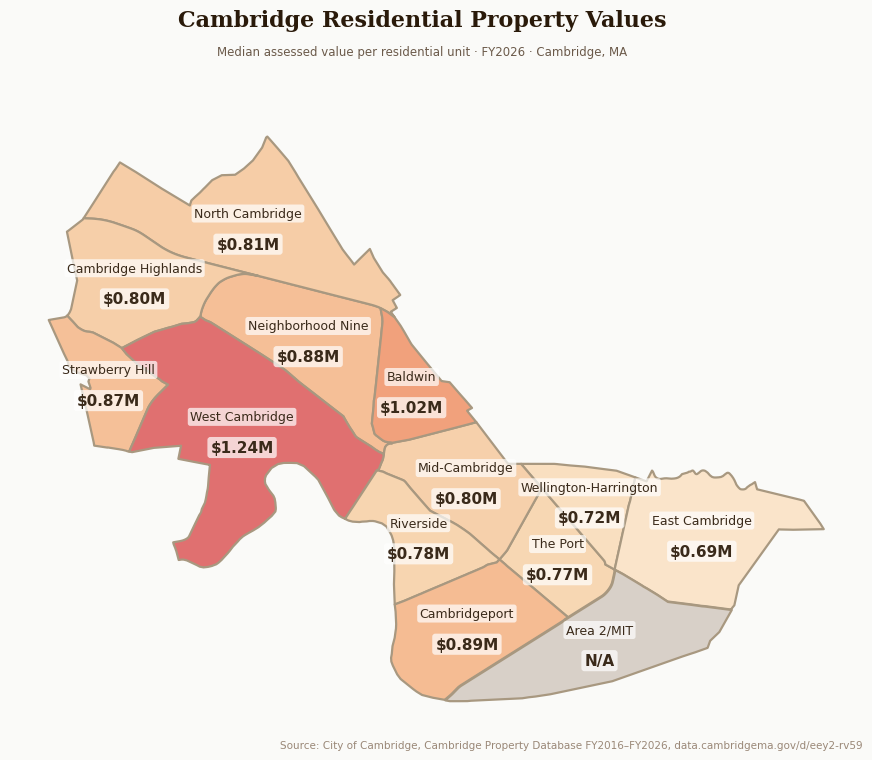

Saved → data/out/assessed_value_per_unit_map.png


In [6]:
# ── Tweak these ──────────────────────────────────────────────────────────────
TITLE    = "Cambridge Residential Property Values"
SUBTITLE = "Median assessed value per residential unit · FY2026 · Cambridge, MA"
OUT_PATH = DATA_OUT / "assessed_value_per_unit_map.png"
CMAP     = LinearSegmentedColormap.from_list("val_orange",
               ["#fff8f0", "#f7d9b5", "#f4a97e", "#e07070"])
GAMMA    = 0.8
VMIN     = 600_000   # anchor below data floor (~$694k) so full range uses full colormap
# ─────────────────────────────────────────────────────────────────────────────

val_by_nbhd = (
    joined[joined['neighborhood'].notna() & (joined['neighborhood'] != MIT_NAME)]
    .groupby('neighborhood')['value_per_unit']
    .median()
    .reset_index()
    .rename(columns={'neighborhood': 'NAME', 'value_per_unit': 'value'})
)
map_gdf = neighborhoods_utm.merge(val_by_nbhd, on='NAME', how='left')

draw_choropleth(
    map_gdf,
    cmap=CMAP,
    norm=PowerNorm(gamma=GAMMA, vmin=VMIN, vmax=map_gdf['value'].max()),
    edge_color="#a89880",
    txt_color="#3a2a1a",
    label_fn=lambda v: f"${v/1e6:.2f}M",
    title=TITLE, subtitle=SUBTITLE, out_path=OUT_PATH,
)

## Choropleth: average units per residential building

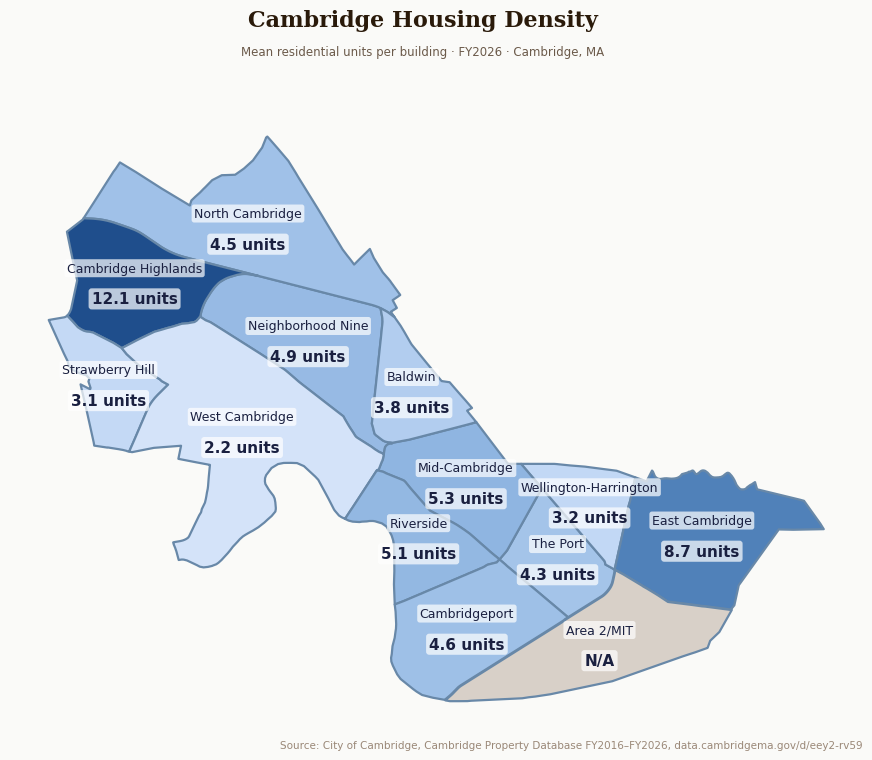

Saved → data/out/units_per_building_map.png


In [7]:
# ── Tweak these ──────────────────────────────────────────────────────────────
TITLE    = "Cambridge Housing Density"
SUBTITLE = "Mean residential units per building · FY2026 · Cambridge, MA"
OUT_PATH = DATA_OUT / "units_per_building_map.png"
CMAP     = LinearSegmentedColormap.from_list("units_blue",
               ["#f0f5ff", "#c2d8f5", "#6e9fd4", "#1f4e8c"])
GAMMA    = 0.6
VMIN     = 1.5   # anchor below data floor (~2.2) so West Cambridge reads as light
# ─────────────────────────────────────────────────────────────────────────────

map_gdf = neighborhoods_utm.merge(
    mean_units_by_nbhd.reset_index().rename(columns={'mean_units': 'value'}),
    on='NAME', how='left',
)

draw_choropleth(
    map_gdf,
    cmap=CMAP,
    norm=PowerNorm(gamma=GAMMA, vmin=VMIN, vmax=map_gdf['value'].max()),
    edge_color="#6888a8",
    txt_color="#1a2040",
    label_fn=lambda v: f"{v:.1f} units",
    title=TITLE, subtitle=SUBTITLE, out_path=OUT_PATH,
)

## Choropleth: % single-family homes

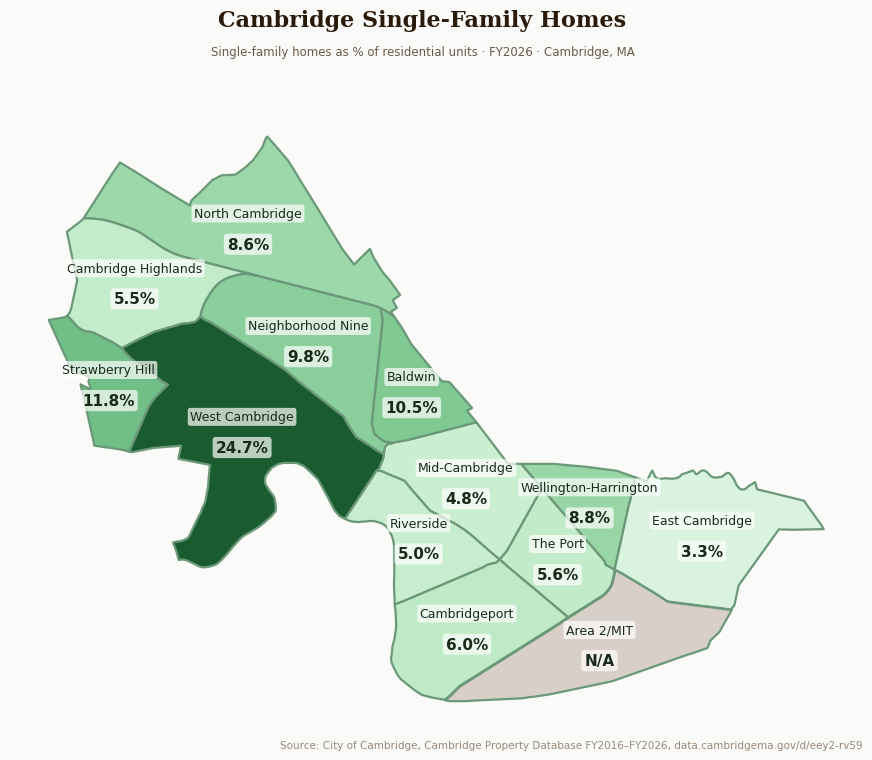

Saved → data/out/pct_sfh_map.png


In [8]:
# ── Tweak these ──────────────────────────────────────────────────────────────
TITLE    = "Cambridge Single-Family Homes"
SUBTITLE = "Single-family homes as % of residential units · FY2026 · Cambridge, MA"
OUT_PATH = DATA_OUT / "pct_sfh_map.png"
CMAP     = LinearSegmentedColormap.from_list("sfh_green",
               ["#f0faf2", "#b8e8c0", "#4caa68", "#1a5c30"])
GAMMA    = 0.7
VMIN     = 2.0   # anchor below data floor (~3.3%) so full range is used
# ─────────────────────────────────────────────────────────────────────────────

map_gdf = neighborhoods_utm.merge(
    pct_sfh_by_nbhd.reset_index().rename(columns={'pct_sfh': 'value'}),
    on='NAME', how='left',
)

draw_choropleth(
    map_gdf,
    cmap=CMAP,
    norm=PowerNorm(gamma=GAMMA, vmin=VMIN, vmax=map_gdf['value'].max()),
    edge_color="#6a9878",
    txt_color="#1a2a1a",
    label_fn=lambda v: f"{v:.1f}%",
    title=TITLE, subtitle=SUBTITLE, out_path=OUT_PATH,
)

---

---

# Exploratory analysis *(lower fidelity)*

The section below — assessed value distributions across selected neighborhoods — is a working analysis rather than a publication-ready output. Methodology choices are documented inline. It has not been externally validated and the visualization may need tuning before use.

**West Cambridge tenure and tax equity analysis has been moved to `03_west_cambridge_equity.ipynb`.**

---


## Distribution of residential property values by neighborhood

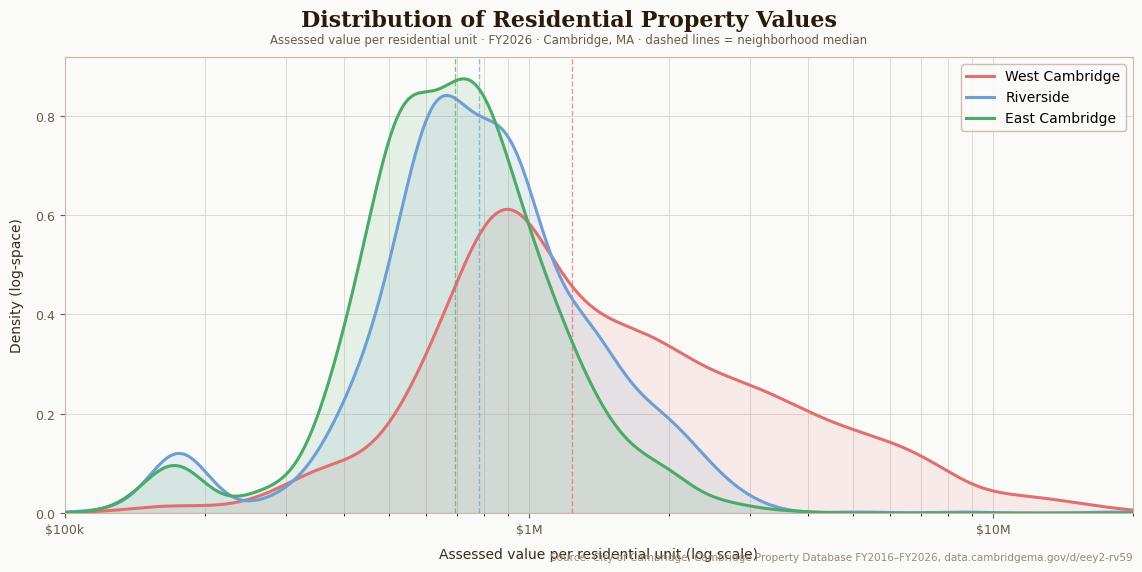

Saved → data/out/value_distribution.png


In [9]:
import numpy as np
from scipy.stats import gaussian_kde

# ── Tweak these ──────────────────────────────────────────────────────────────
NEIGHBORHOODS = ["West Cambridge", "Riverside", "East Cambridge"]
COLORS        = ["#e07070", "#6e9fd4", "#4caa68"]
X_MIN         = 100_000     # excludes only extreme outliers (parking spaces etc.)
X_MAX         = 20_000_000  # West Cambridge reaches ~$19M
OUT_PATH      = DATA_OUT / "value_distribution.png"
# ─────────────────────────────────────────────────────────────────────────────

# Log-spaced grid matches the log x-axis: equal point density across decades
x_grid = np.logspace(np.log10(X_MIN), np.log10(X_MAX), 1000)

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#fafaf8")
ax.set_facecolor("#fafaf8")
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.08, right=0.97)

for nbhd, color in zip(NEIGHBORHOODS, COLORS):
    vals = (
        joined[(joined['neighborhood'] == nbhd) & joined['value_per_unit'].notna()]
        ['value_per_unit']
        .pipe(lambda s: s[s >= X_MIN])
    )
    log_v   = np.log(vals)
    kde     = gaussian_kde(log_v)
    # On a log x-axis, plot the log-space density directly (not Jacobian-transformed):
    # makes a log-normal appear as a symmetric bell and spreads the affordable-unit clusters.
    density = kde(np.log(x_grid))
    ax.plot(x_grid, density, color=color, linewidth=2.2, label=nbhd, zorder=3)
    ax.fill_between(x_grid, density, alpha=0.12, color=color, zorder=2)
    ax.axvline(vals.median(), color=color, linewidth=1, linestyle="--", alpha=0.7, zorder=3)

ax.set_xscale("log")
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda x, _: f"${x/1e6:.0f}M" if x >= 1e6 else f"${x/1e3:.0f}k"
))
ax.set_xlabel("Assessed value per residential unit (log scale)", fontsize=10, color="#3a2a1a", labelpad=8)
ax.set_ylabel("Density (log-space)", fontsize=10, color="#3a2a1a", labelpad=8)
ax.tick_params(colors="#6a5a4a", labelsize=9)
ax.grid(axis="y", color="#e0d8d0", linewidth=0.7, zorder=0)
ax.grid(axis="x", color="#e0d8d0", linewidth=0.7, which="both", zorder=0)
for spine in ax.spines.values():
    spine.set_edgecolor("#c8b8a8")

ax.legend(fontsize=10, framealpha=0.9, edgecolor="#c8b8a8", facecolor="#fafaf8")

fig.text(0.5, 0.96, "Distribution of Residential Property Values",
         ha="center", va="top", fontsize=16, fontweight="bold",
         color="#2a1a0a", fontfamily=SERIF)
fig.text(0.5, 0.92,
         "Assessed value per residential unit · FY2026 · Cambridge, MA"
         " · dashed lines = neighborhood median",
         ha="center", va="top", fontsize=8.5, color="#6b5a4a")
ax.annotate(SOURCE_STR, xy=(1, 0), xycoords="axes fraction",
            ha="right", va="top", fontsize=7.5, color="#9a8878",
            xytext=(0, -28), textcoords="offset points")

plt.savefig(OUT_PATH, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print(f"Saved → {OUT_PATH}")